In [1]:
%matplotlib notebook
from IPython.display import Image, display_png
from rdkit.Chem.Draw import IPythonConsole
import pickle
from rdkit import Chem
from rdkit.Chem.PandasTools import LoadSDF
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import copy
import json
import pandas as pd
import pandas.io.formats.html
import os
from sklearn import mixture
import seaborn as sns
import scipy
from rdkit.Chem import rdqueries
import metadisassembler5 as medi4

In [2]:
with open('data/translator.json', 'r') as f:
    translator = json.load(f)

In [3]:
import rdkit
print(rdkit.__version__)

2021.09.5


In [9]:
#import pickletools
#aux = None
#with open('/home/ubuntu/Juanlu/MLProjects/kegg-matrix/data_kegg_matrix/molecules_kegg.pkl', 'rb') as f:
    #data = f.read()
    #for opcode, arg, pos in pickletools.genops(data):
        #if opcode.name == 'PROTO':
            #version = arg
            #break

#print(f'This pickle file was created using pickle version {version}')

This pickle file was created using pickle version 3


In [ ]:
#with open('/home/ubuntu/Juanlu/MLProjects/kegg-matrix/data_kegg_matrix/molecules_kegg.pkl', 'rb') as f:
    #data = f.read()
    #bytecode = pickletools.dis(data)
    #version = bytecode[0][2]
#print(f'This pickle file was created using pickle version {version}')

In [14]:
pickle.format_version

'4.0'

In [4]:
with open('/home/ubuntu/Juanlu/MLProjects/kegg-matrix/data_kegg_matrix/molecules_kegg.pkl', 'rb') as f:
    molecules = pickle.load(f, fix_imports=True)

In [ ]:
molecules

In [8]:
with open('names_kegg.pkl', 'rb') as f:
    names = pickle.load(f)

In [9]:
for i, name in enumerate(names):
    if 'C12043' in name:
        print(i)

8555


In [10]:
Chem.MolToInchi(molecules[8555])

'InChI=1S/C53H93N7O13/c1-30(2)20-18-16-14-13-15-17-19-21-36-28-43(61)54-37(22-23-44(62)63)47(66)55-38(24-31(3)4)48(67)57-40(26-33(7)8)51(70)60-46(35(11)12)52(71)58-41(29-45(64)65)50(69)56-39(25-32(5)6)49(68)59-42(27-34(9)10)53(72)73-36/h30-42,46H,13-29H2,1-12H3,(H,54,61)(H,55,66)(H,56,69)(H,57,67)(H,58,71)(H,59,68)(H,60,70)(H,62,63)(H,64,65)/t36-,37+,38+,39-,40-,41+,42+,46+/m1/s1'

# 1 Re-Analysis

Features: in degree, out degree, reactions and NCarbons. Does any combination of these features an explainable particularity of the already chosen PBUs?

In [ ]:
df_clean = pd.read_csv('PBU_analysis/df_clean.csv').rename(columns={'Unnamed: 0':'ID'})
df_clean = df_clean.set_index('ID')
df_clean.head()

In [8]:
df_clean.loc['kegg_701']

Connections_out         252.0
Connections_in           33.0
MWeight            160.084792
NCarbons                    6
PBU                     False
Reactions                   4
Name: kegg_701, dtype: object

<IPython.core.display.Javascript object>


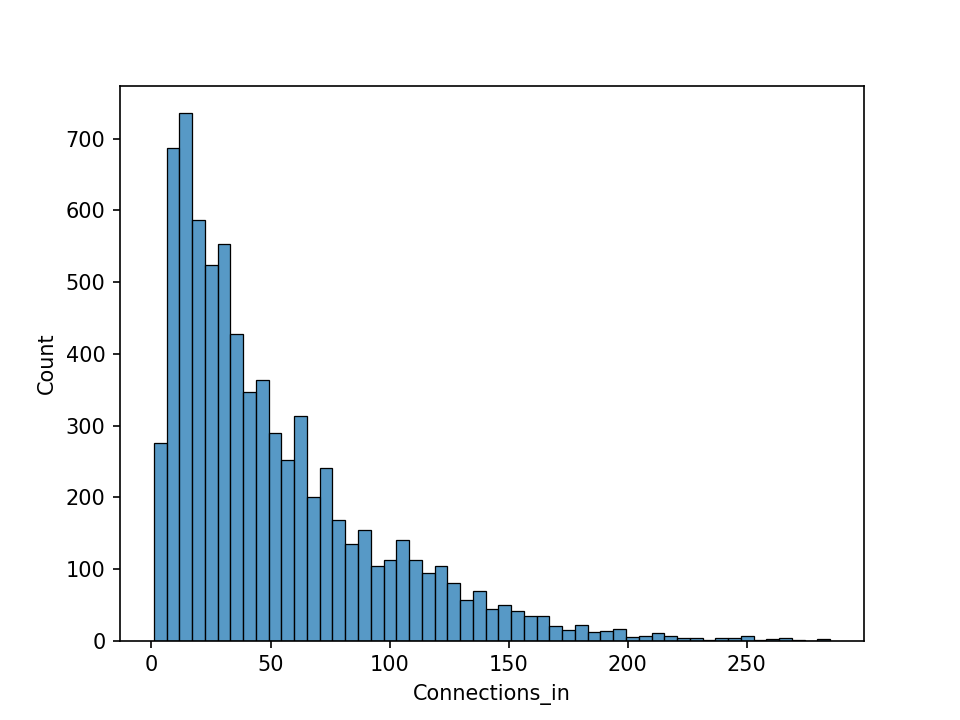

In [9]:
# Visualisation of the In Degree

sns.histplot(df_clean['Connections_in'])

In [10]:
df_clean.shape

(7498, 6)

In [11]:
df_clean['logOut'] = np.log(df_clean['Connections_out'].values+1)
df_clean['logReactions'] = np.log(df_clean['Reactions'].values+1)
df_clean['logIn'] = np.log(df_clean['Connections_in'].values+1)
df_clean['logCarbons'] = np.log(df_clean['NCarbons'].values+1)

It seems that the structures chosen as PBUs are in a low density zone, as if they where anomalies

In [ ]:
plt.figure()
sns.boxplot(x='PBU', y='Reactions', data=df_clean, showfliers = False)
plt.figure()
sns.boxplot(x='PBU', y='Connections_in', data=df_clean, showfliers = False)
plt.figure()
sns.boxplot(x='PBU', y='Connections_out', data=df_clean, showfliers = False)
plt.figure()
sns.boxplot(x='PBU', y='NCarbons', data=df_clean, showfliers = False)

In [ ]:
plt.figure()
sns.boxplot(x='PBU', y='logReactions', data=df_clean, showfliers = True)
plt.figure()
sns.boxplot(x='PBU', y='logIn', data=df_clean, showfliers = True)
plt.figure()
sns.boxplot(x='PBU', y='logOut', data=df_clean, showfliers = True)

In [ ]:
plt.figure()
sns.boxplot(x='BRITE', y='logReactions', data=df_clean, showfliers = True)
plt.figure()
sns.boxplot(x='BRITE', y='logIn', data=df_clean, showfliers = True)
plt.figure()
sns.boxplot(x='BRITE', y='logOut', data=df_clean, showfliers = True)
plt.figure()
sns.boxplot(x='BRITE', y='logCarbons', data=df_clean, showfliers = True)

<IPython.core.display.Javascript object>


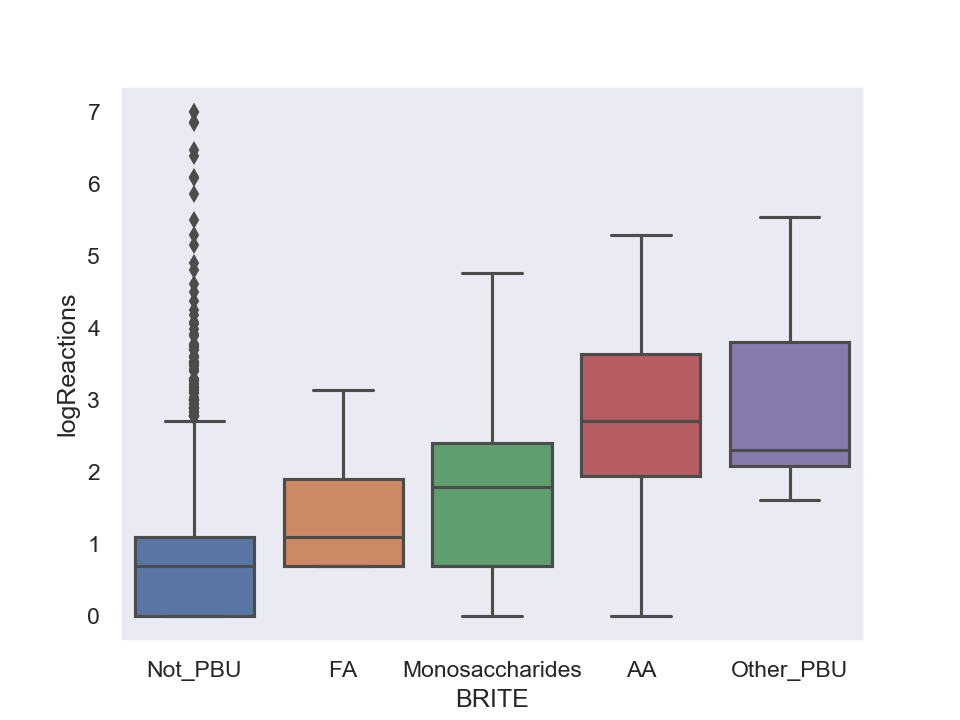

<IPython.core.display.Javascript object>


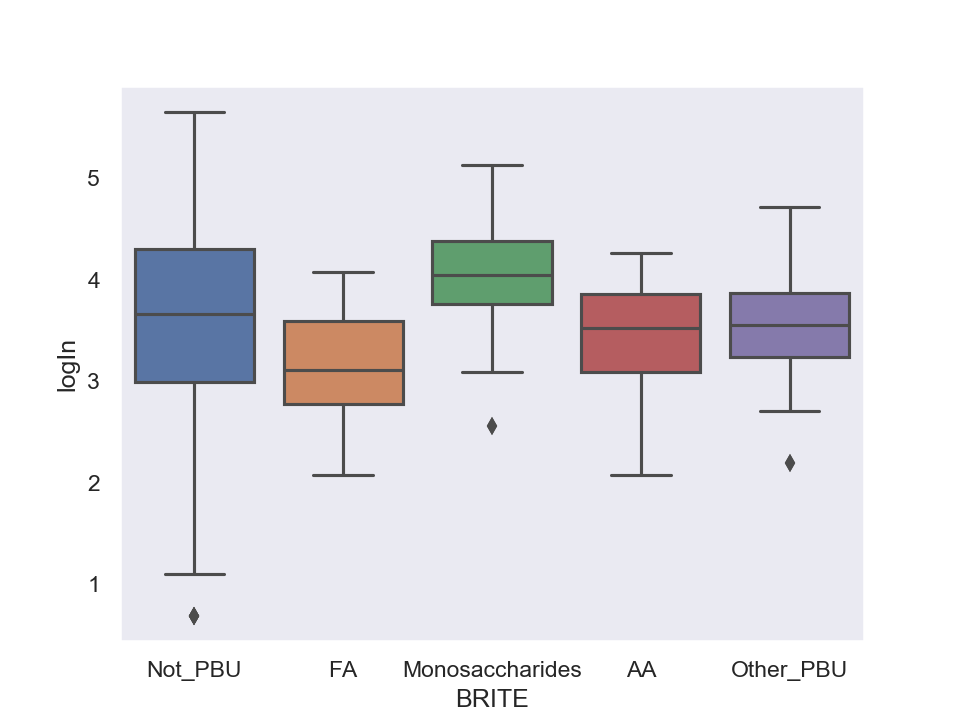

<IPython.core.display.Javascript object>


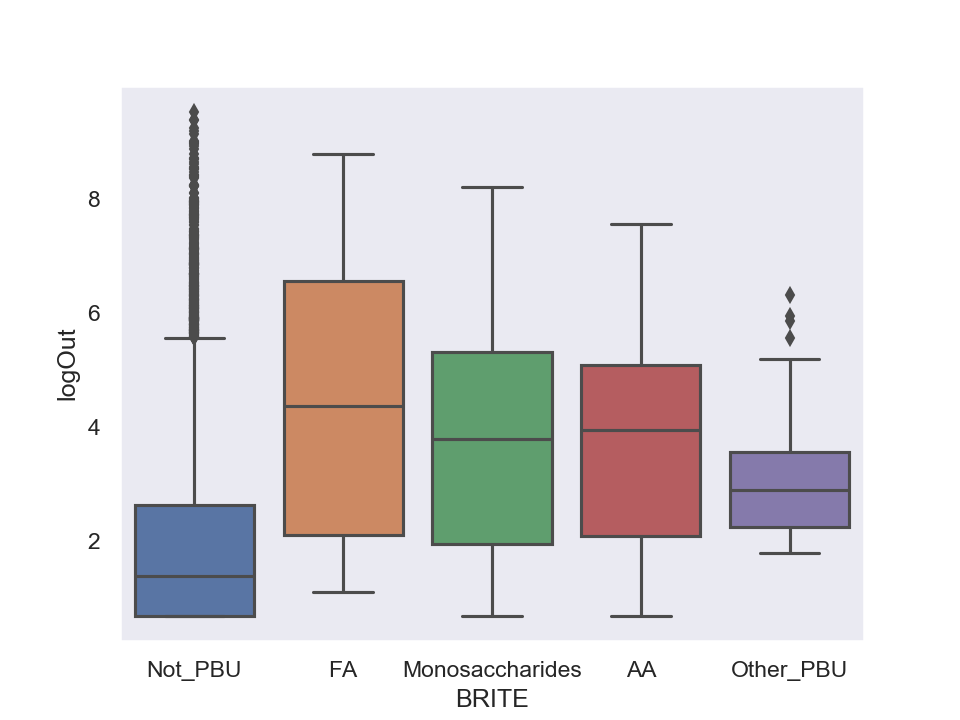

<IPython.core.display.Javascript object>


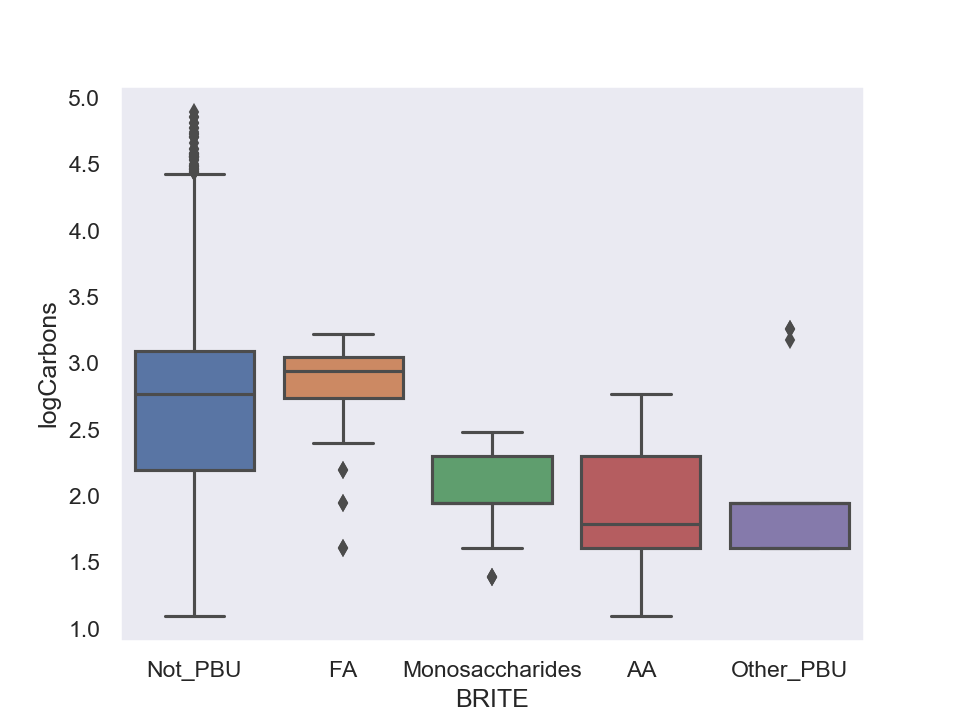

In [35]:
plt.figure()
sns.boxplot(x='BRITE', y='logReactions', data=df_clean, showfliers = True)
plt.figure()
sns.boxplot(x='BRITE', y='logIn', data=df_clean, showfliers = True)
plt.figure()
sns.boxplot(x='BRITE', y='logOut', data=df_clean, showfliers = True)
plt.figure()
sns.boxplot(x='BRITE', y='logCarbons', data=df_clean, showfliers = True)

In [12]:
df_clean[df_clean['BRITE'] == 'FA'].index

KeyError: 'BRITE'

In [81]:
translator['kegg_1204']

['C01838', 'C01530_mod_0']

Chosen PBUs have as in degree as the rest of kegg, more out degree and more reactions

<IPython.core.display.Javascript object>


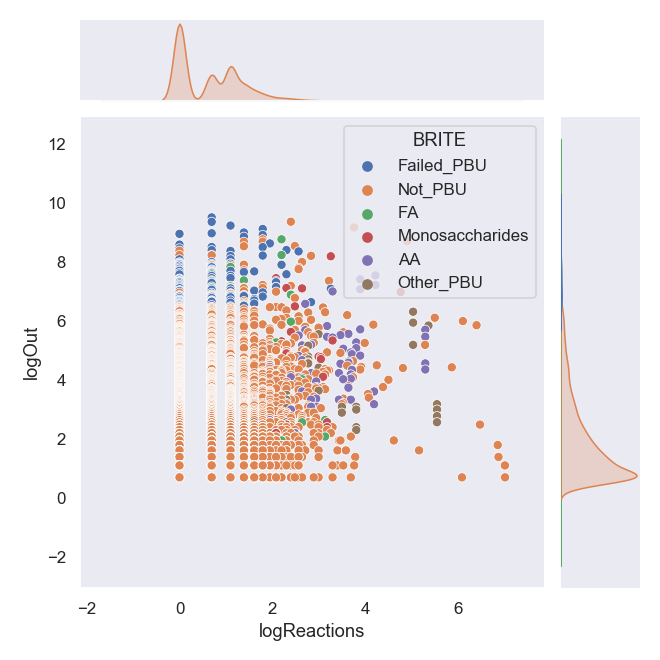

In [86]:
plot = sns.jointplot(data=df_clean, x='logReactions', y ='logOut', hue='BRITE')

<IPython.core.display.Javascript object>


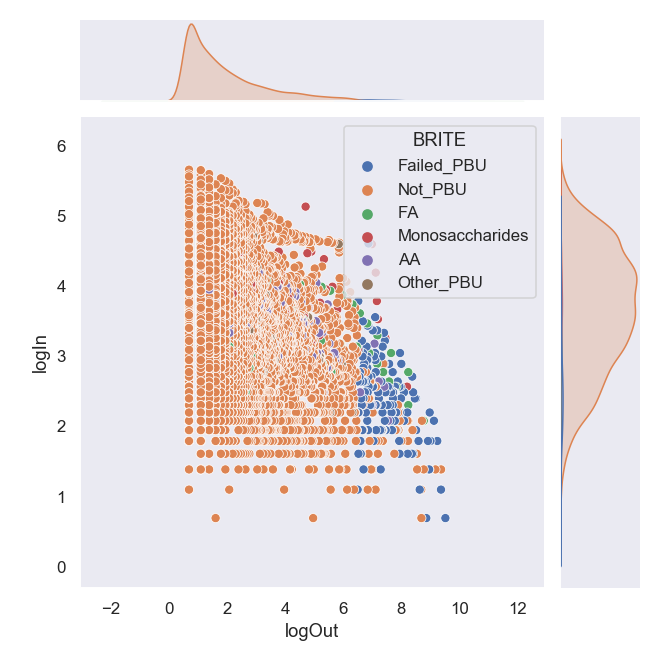

In [87]:
plot = sns.jointplot(data=df_clean, x='logOut', y ='logIn', hue='BRITE')

<IPython.core.display.Javascript object>


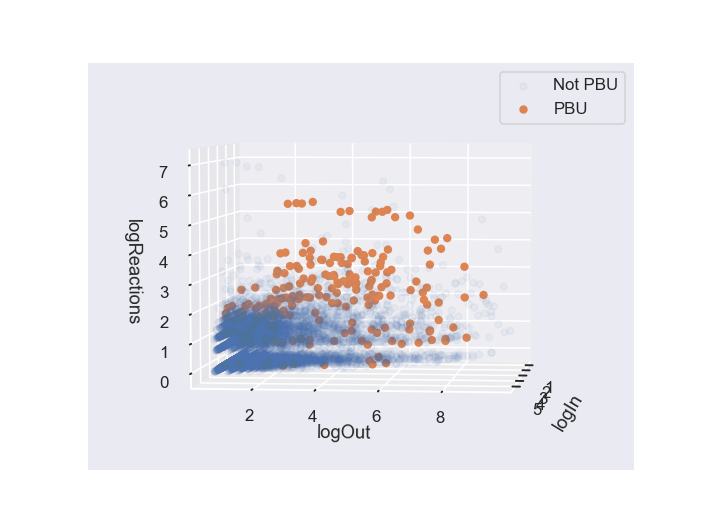

In [11]:

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

sns.set(style = "dark")

fig = plt.figure()
ax = fig.add_subplot(111, projection = '3d')

x = df_clean[df_clean['PBU'] == False]['logIn']
y = df_clean[df_clean['PBU'] == False]['logOut']
z = df_clean[df_clean['PBU'] == False]['logReactions']

ax.set_xlabel("logIn")
ax.set_ylabel("logOut")
ax.set_zlabel("logReactions")

ax.scatter(x, y, z, label='Not PBU', alpha=0.05)


x = df_clean[df_clean['PBU'] == True]['logIn']
y = df_clean[df_clean['PBU'] == True]['logOut']
z = df_clean[df_clean['PBU'] == True]['logReactions']

ax.scatter(x, y, z, label='PBU', alpha=1)
ax.legend()

Some conclusions from the graph above:
- Aminoacid are more reactive
- Fatty acids are larger and the less reactive
- Monosaccharides are in between the other two groups
- In the previous analysis, the reactions were not taken into account leading to a group of PBU with very low reactions. Moreover, the logIn of the molecules was not taken into account, which resulted into molecules with vey log inDegree.

In [13]:
df_clean[df_clean['PBU'] == True].shape

(225, 10)

In [18]:
X_train = np.zeros((df_clean.shape[0], 2))
X_train[:, 0] = df_clean['logOut'].values
X_train[:, 1] = df_clean['logReactions'].values
Y_train = np.array(df_clean['PBU'].values)

In [21]:
from sklearn.ensemble import RandomForestClassifier
from matplotlib.colors import ListedColormap
rf = RandomForestClassifier(n_estimators=2)
rf.fit(X_train, Y_train)
plot_step = 0.02
x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(
            np.arange(x_min, x_max, plot_step), np.arange(y_min, y_max, plot_step)
        )
cmap = plt.cm.RdYlBu
estimator_alpha = 1.0 / len(rf.estimators_)
for tree in rf.estimators_:
    Z = tree.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, alpha=estimator_alpha, cmap=cmap)
    
plt.scatter(
            X_train[:, 0],
            X_train[:, 1],
            c=Y_train,
            cmap=ListedColormap(["r", "y", "b"]),
            edgecolor="k",
            s=20,
        )

<IPython.core.display.Javascript object>


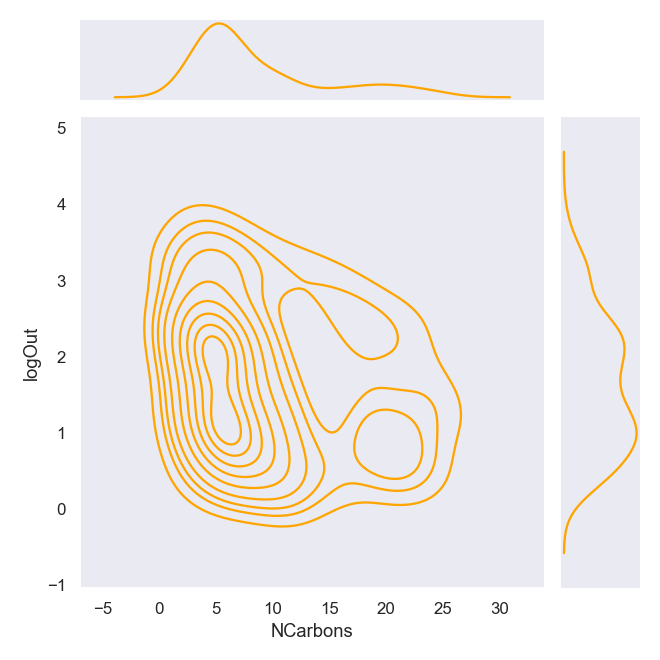

In [22]:
plot = sns.jointplot(data=df_clean[df_clean['PBU']==True], x='NCarbons', y ='logOut',  kind="kde", color='orange')

<IPython.core.display.Javascript object>


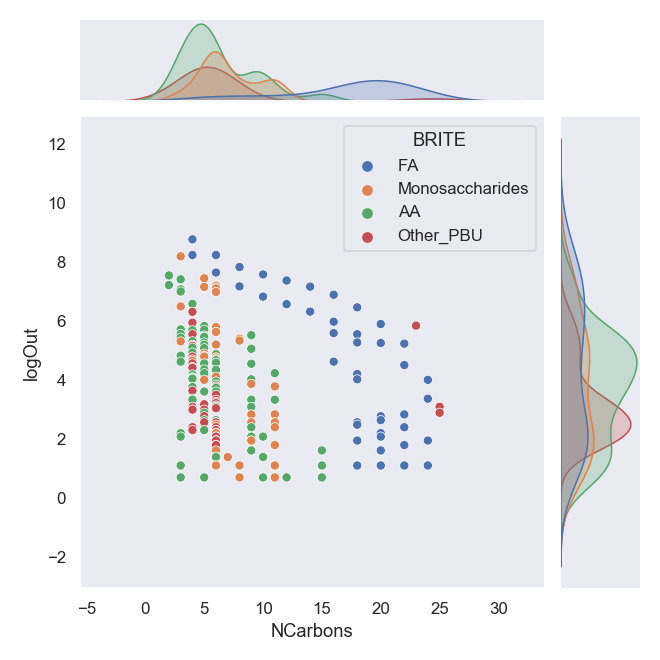

In [93]:
plot = sns.jointplot(data=df_clean[df_clean['PBU']==True], x='NCarbons', y ='logOut', color='orange', hue='BRITE')

<IPython.core.display.Javascript object>


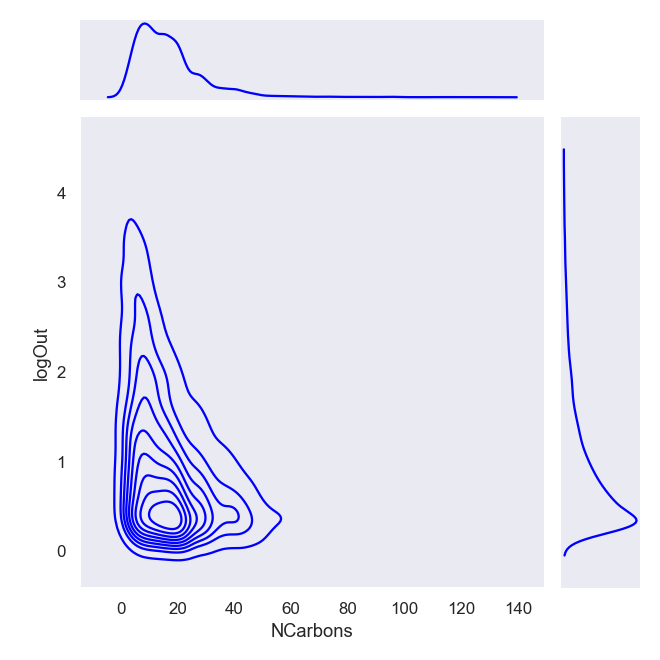

In [24]:
plot = sns.jointplot(data=df_clean[df_clean['PBU']==False], x='NCarbons', y ='logOut',  kind="kde", color='blue')

In [25]:
print('Very Reactive Compounds')
for index in df_clean[df_clean['Reactions'] > 200].index:
    print('Compound: ' + str(translator[index]) + ', PBU? ' + str(df_clean.loc[index]['PBU']))

Very Reactive Compounds
Compound: ['C00020'], PBU? False
Compound: ['C00008'], PBU? False
Compound: ['C00010'], PBU? False
Compound: ['C00024'], PBU? True
Compound: ['C00015'], PBU? False
Compound: ['C00026_mod_1', 'C00026_mod_3'], PBU? True
Compound: ['C00433', 'C00026_mod_2'], PBU? True
Compound: ['C02800', 'C00026_mod_0'], PBU? True
Compound: ['C00026'], PBU? True
Compound: ['C00002'], PBU? False
Compound: ['C00004'], PBU? False
Compound: ['C00003'], PBU? False
Compound: ['C00005'], PBU? False
Compound: ['C00021'], PBU? False
Compound: ['C00006'], PBU? False


In [19]:
df_clean['New_var'] = np.absolute(df_clean['Connections_out'].values * df_clean['Reactions'].values) 

In [20]:
df_clean.head()

,Connections_out,Connections_in,MWeight,NCarbons,PBU,Reactions,New_var
ID,,,,,,,
kegg_15303,13688.0,1.0,44.062600,3,False,1,13688.0
kegg_348,11805.0,3.0,46.041865,2,False,10,118050.0
kegg_15775,11760.0,2.0,58.078250,4,False,1,11760.0
kegg_3314,10355.0,5.0,60.057515,3,False,2,20710.0
kegg_68,9719.0,3.0,44.026215,2,False,42,408198.0


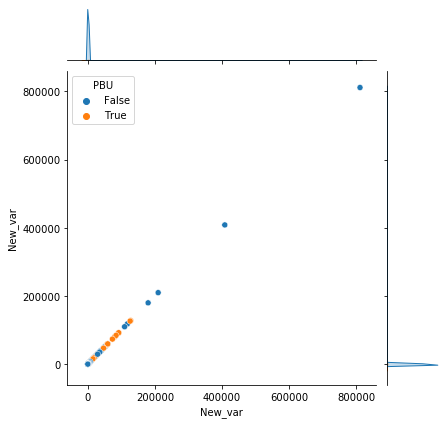

In [21]:
sns.jointplot(data=df_clean, x='New_var', y ='New_var', hue='PBU')


As expected, the chosen PBUs are more 'reactives'.

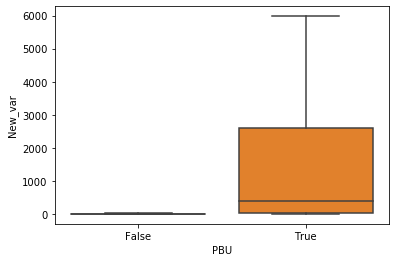

In [22]:
plt.figure()
sns.boxplot(x='PBU', y='New_var', data=df_clean, showfliers = False)
#plt.ylim([0, 8000])

In [39]:
from scipy.stats import norm
loc1, scale1 = norm.fit(df_clean[df_clean['PBU'] == True]['New_var'].values)
loc1, scale1

(6173.56, 18798.162661215356)

# 2. Selection Criteria developement

Let us start by defining some boundaries below which the molecular structures will be rejected as possible PBUs

In [136]:
def prob_pbu(x, *args):
    aux1 = df_clean[df_clean['PBU'] == True].shape[0]
    aux2 = df_clean[df_clean['PBU'] == False].shape[0]
    
    x_lim = df_clean[df_clean['PBU'] == True]['logIn'].quantile(x[0])
    y_lim = df_clean[df_clean['PBU'] == True]['logOut'].quantile(x[1])
    z_lim = df_clean[df_clean['PBU'] == True]['logReactions'].quantile(0.9)
    
    a = (df_clean[df_clean['PBU'] == True][df_clean['logIn']>x_lim].shape[0]/aux1)/(df_clean[df_clean['PBU'] == False][df_clean['logIn']>x_lim].shape[0]/aux2)
    b = (df_clean[df_clean['PBU'] == True][df_clean['logOut']>y_lim].shape[0]/aux1)/(df_clean[df_clean['PBU'] == False][df_clean['logOut']>y_lim].shape[0]/aux2)
    c = (df_clean[df_clean['PBU'] == True][df_clean['logReactions']>z_lim].shape[0]/aux1)/(df_clean[df_clean['PBU'] == False][df_clean['logReactions']>z_lim].shape[0]/aux2)
    
    return -1/3 * (a + b + c)

In [174]:
def prob_pbu(X, Y):
    aux1 = df_clean[df_clean['PBU'] == True].shape[0]
    aux2 = df_clean[df_clean['PBU'] == False].shape[0]
    
    x_lim = df_clean[df_clean['PBU'] == True]['logIn'].quantile(X)
    y_lim = df_clean[df_clean['PBU'] == True]['logOut'].quantile(0.9)
    z_lim = df_clean[df_clean['PBU'] == True]['logReactions'].quantile(Y)
    
    a = (df_clean[df_clean['PBU'] == True][df_clean['logIn']>x_lim].shape[0]/aux1)/(df_clean[df_clean['PBU'] == False][df_clean['logIn']>x_lim].shape[0]/aux2)
    b = (df_clean[df_clean['PBU'] == True][df_clean['logOut']>y_lim].shape[0]/aux1)/(df_clean[df_clean['PBU'] == False][df_clean['logOut']>y_lim].shape[0]/aux2)
    c = (df_clean[df_clean['PBU'] == True][df_clean['logReactions']>z_lim].shape[0]/aux1)/(df_clean[df_clean['PBU'] == False][df_clean['logReactions']>z_lim].shape[0]/aux2)
    
    return 1/3 * (a + b + c)

C:\Users\idener\anaconda3\envs\metadisassembler\lib\site-packages\ipykernel_launcher.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  if __name__ == '__main__':
C:\Users\idener\anaconda3\envs\metadisassembler\lib\site-packages\ipykernel_launcher.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  # Remove the CWD from sys.path while we load stuff.
C:\Users\idener\anaconda3\envs\metadisassembler\lib\site-packages\ipykernel_launcher.py:11: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  # This is added back by InteractiveShellApp.init_path()


<IPython.core.display.Javascript object>


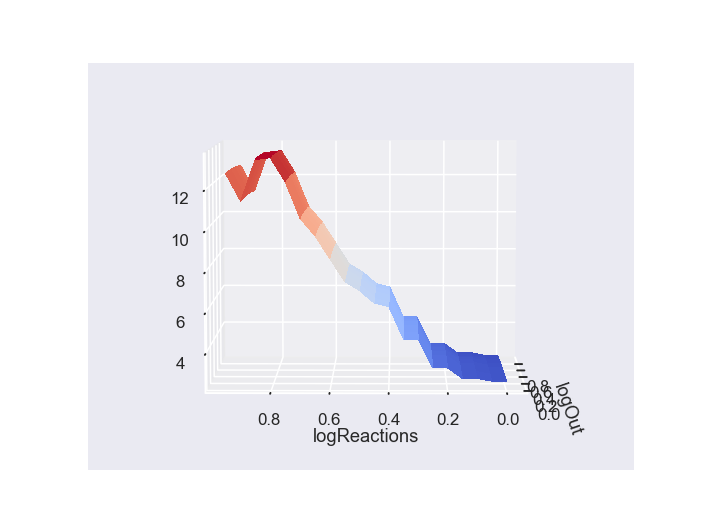

Text(0.5, 0, 'logReactions')

In [175]:
from matplotlib import cm

X = np.arange(0, 0.99, 0.05)
Y = np.arange(0, 0.99, 0.05)
X, Y = np.meshgrid(X, Y)

Z = np.zeros((X.shape[0], X.shape[0]))
for i in range(X.shape[0]):
    for j in range(X.shape[0]):
        Z[i,j] = prob_pbu(X[i, j], Y[i,j ])

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
surf = ax.plot_surface(X, Y, np.array(Z), cmap=cm.coolwarm,
                       linewidth=0, antialiased=False)
ax.set_xlabel("logOut")
ax.set_ylabel("logReactions")

In [161]:
Y.shape

(20, 20)

In [150]:
from scipy.optimize import minimize

res = minimize(prob_pbu, [0.8 ,0.8, 0.9], args=df_clean, method ='Nelder-Mead')

C:\Users\idener\anaconda3\envs\metadisassembler\lib\site-packages\ipykernel_launcher.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  if __name__ == '__main__':
C:\Users\idener\anaconda3\envs\metadisassembler\lib\site-packages\ipykernel_launcher.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  if sys.path[0] == '':
C:\Users\idener\anaconda3\envs\metadisassembler\lib\site-packages\ipykernel_launcher.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  


4.040555555555556
28.283888888888892
4.040555555555556
28.283888888888892
3.6942222222222223
28.283888888888892
4.040555555555556
28.014518518518514
4.195961538461538
26.93703703703704
3.8979477124183006
28.283888888888892
3.8979477124183006
32.324444444444445
3.8979477124183006
34.02573099415205
4.185258647076829
34.409892473118276
4.060859854829704
34.68964769647697
4.040555555555556
32.98412698412699
4.040555555555556
25.782592592592593
4.040555555555556
34.409892473118276
4.040555555555556
32.324444444444445
4.040555555555556
34.68964769647697
4.08971073263044
34.02573099415205
4.060859854829704
34.02573099415205
4.216231884057971
34.68964769647697
4.040555555555556
34.02573099415205
4.005622798591099
34.81094017094017
4.040555555555556
33.69995271867612
4.040555555555556
34.81094017094017
4.040555555555556
34.81094017094017
4.1140202020202015
34.81094017094017
4.150299039780521
34.81094017094017
4.1110889443059015
34.68964769647697
4.185258647076829
34.81094017094017
4.09968563685

 final_simplex: (array([[0.85554989, 0.79013117, 0.81319382],
       [0.85551753, 0.79017687, 0.813193  ],
       [0.85552732, 0.79016523, 0.81320438],
       [0.8555317 , 0.79014603, 0.81319748]]), array([-13.16980278, -13.16980278, -13.16980278, -13.16980278]))
           fun: -13.169802780639325
       message: 'Optimization terminated successfully.'
          nfev: 78
           nit: 26
        status: 0
       success: True
             x: array([0.85554989, 0.79013117, 0.81319382])

In [15]:
top_bound = 0.3
# bottom_bound = 1 - top_bound
bottom_bound = 1
x_lim = df_clean[df_clean['PBU'] == True]['logIn'].quantile(top_bound)
y_lim = df_clean[df_clean['PBU'] == True]['logOut'].quantile(.3)
z_lim = df_clean[df_clean['PBU'] == True]['logReactions'].quantile(0.3)
df_not_pbu = df_clean[df_clean['PBU'] == False]
new_pbus = list(df_not_pbu[df_not_pbu['logIn'] >= x_lim][df_not_pbu['logOut'] >= y_lim][df_not_pbu['logReactions'] >= z_lim].index)

C:\Users\idener\anaconda3\envs\metadisassembler\lib\site-packages\ipykernel_launcher.py:8: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  


In [18]:
y_lim

2.321647128954911

In [262]:
len(new_pbus)

237

<IPython.core.display.Javascript object>


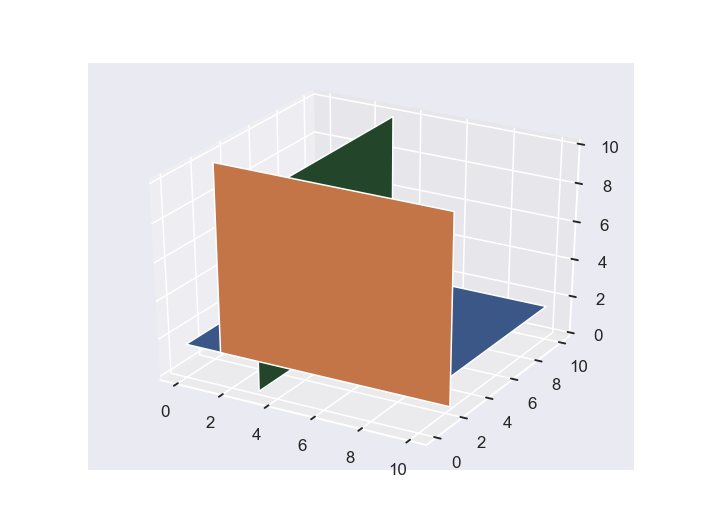

In [263]:
xx, yy = np.meshgrid(np.linspace(0, 10, 2), np.linspace(0, 10, 2))

fig = plt.figure()
ax = fig.add_subplot(111, projection = '3d')
ax.plot_surface(xx, yy, z_lim*np.ones((xx.shape[0], yy.shape[0])))
ax.plot_surface(xx, y_lim*np.ones((xx.shape[0], yy.shape[0])), yy)
ax.plot_surface(x_lim*np.ones((xx.shape[0], yy.shape[0])), xx, yy)

In [216]:
with open('pbu_codes.pkl', 'rb') as f:
    pbu_codes = pickle.load(f)

In [217]:
mod_ids = []
for key, value in translator.items():
    for code in pbu_codes:
        if code in value:
            if key not in mod_ids:
                mod_ids.append(key)
mod_ids[0:5]

['kegg_21', 'kegg_22', 'kegg_23', 'kegg_26', 'kegg_31']

# 3. Kegg BRITE hierarchy analysis

In [22]:
with open('BRITE.json', 'r') as f:
    BRITE = json.load(f)

In [23]:
def find_hierarchy(ddd, query):
    matches_list = []
    for child in ddd['children']:
        matches = extract_hierarchy(child, query)
        if matches:
            matches_list.append(matches)
            
    if matches_list:
        return {'name': ddd['name'], 'children': matches_list}
    else:
        return None
    
def extract_hierarchy(elem, query):
    # Check if the children of the current element has children
    if 'children' in elem:
        matches_list = []
        # Get all the matches in the children
        for child in elem['children']:
            matches = extract_hierarchy(child, query)
            if matches:
                matches_list.append(matches)
        # If there were matches, return the current element and its children
        if matches_list:
            return {'name': elem['name'], 'children': matches_list}
        # If there were no matches, return an empty object
        else:
            return None
    # If there are no children, check if the element matches with the query
    else:
        if query in elem['name']:
            return elem
        else:
            return None
        
def post_process_hierarchy(result, hierarchies, j):
    
    if 'children' in result.keys():
        for elem in result['children']:
            hierarchies[j].append(result['name'])
            hierarchies = post_process_hierarchy(elem, hierarchies, j)
            j+=1
            hierarchies[j] = []
    else:
        hierarchies[j].append(result['name'])
        
    
    return hierarchies

def get_hierarchy(ddd, query):
    result = find_hierarchy(ddd, query)
    if result:
        hierarchies = {}
        hierarchies[0] = []
        hierarchies = post_process_hierarchy(result, hierarchies, 0)
        to_pop = []
        for key, hierarchy in hierarchies.items():
            if not hierarchy:
                to_pop.append(key)
                
        for popkey in to_pop:
            hierarchies.pop(popkey)
    
        return hierarchies
    else:
        return None
    

In [24]:
def my_bar_percentage_chart(x, h, ylabel=None, xlabel=None, title=None):
    
    plt.figure(figsize=(10, 10))
    
    bars = plt.bar(x, h)
    h_max = max(h)
    bars[np.argmax(h)].set_color('#000000')
    bars[np.argmin(h)].set_color('#ff0000')
    plt.xticks(range(len(x)), x, rotation=45)
    plt.yticks([],[])
    plt.ylabel(ylabel)
    plt.xlabel(xlabel)
    plt.title(title)

    for spine in plt.gca().spines.values():
        spine.set_visible(False)

    for bar in bars:
        plt.gca().text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02*h_max, str(round(bar.get_height(), 2)), ha='center', color='black', rotation=90)
    
    plt.show()

In [12]:
with open('PBU_analysis/new_pbu.pkl', 'rb') as f:
    new_pbu_codes = pickle.load(f)

FileNotFoundError: [Errno 2] No such file or directory: 'PBU_analysis/new_pbu.pkl'

The criterion followed to solved the ambiguity phenomenon related with molecular structures is as follows:
- If the code is unique, take the code (the original or recover the original from the modification)
- If it is not unique and all are original, take the first one.
- If it is not uique and there exists modification take the first modification.

In [26]:
pbu_codes = {}
flag=True
for unique_code in df_clean[df_clean['PBU'] == True].index:
    pbu_codes[unique_code] = []
    if len(translator[unique_code])==1:
        pbu_codes[unique_code].append(translator[unique_code][0].split('_')[0])
    else:
        for element in translator[unique_code]:
            if '_' in list(element):
                pbu_codes[unique_code].append(element.split('_')[0])
                flag=False
                break
        if flag:
            pbu_codes[unique_code].append(translator[unique_code][0])
            
        flag=True

In [27]:
depth = 3
brite = {}
taxonomy = []
brite_flag=False
for key1, value in pbu_codes.items():
    for code in value:
        #print(code)
        hierarchies = get_hierarchy(BRITE, code)
        if hierarchies:
            for key, hierarchy in hierarchies.items():
                taxonomy.append(hierarchy[depth])
                if taxonomy[-1] == 'Amino acids':
                    brite_flag = True
                    tax='AA'
                    break
                if taxonomy[-1] == 'Monosaccharides':
                    brite_flag = True
                    tax = 'Monosaccharides'
                    break
                if taxonomy[-1] == 'Fatty acids [Fig]' or taxonomy[-1] == 'Fatty acids' or taxonomy[-1] == 'FA01 Fatty Acids and Conjugates':
                    brite_flag=True
                    tax = 'FA'
                    break
            if brite_flag:
                brite[key1] = tax
                brite_flag = False
        else:
            taxonomy.append('Not in BRITE')
        
labels, count = np.unique(taxonomy, return_counts = True)
df_counter = pd.DataFrame({'Count':count}, index=labels)
df_counter = df_counter.sort_values(by =['Count'], axis=0, ascending=False)
labels, count = list(df_counter.index), df_counter['Count'].values

In [34]:
lst = []
for index in df_clean.index:
    if index in brite.keys():
        lst.append(brite[index])
    elif df_clean.loc[index]['PBU']:
        lst.append('Other_PBU')
    elif index in new_pbu_codes:
        #lst.append('Failed_PBU')
        lst.append('Not_PBU')
    elif index in new_pbus:
        #lst.append('New_PBU')
        lst.append('Not_PBU')
    else:
        lst.append('Not_PBU')
df_clean['BRITE'] = lst

In [29]:
new_pbus

['kegg_210',
 'kegg_2856',
 'kegg_420',
 'kegg_172',
 'kegg_17',
 'kegg_168',
 'kegg_7',
 'kegg_593',
 'kegg_285',
 'kegg_44',
 'kegg_2965',
 'kegg_799',
 'kegg_629',
 'kegg_9',
 'kegg_212',
 'kegg_4172',
 'kegg_83',
 'kegg_701',
 'kegg_115',
 'kegg_1510',
 'kegg_395',
 'kegg_966',
 'kegg_283',
 'kegg_931',
 'kegg_2884',
 'kegg_91',
 'kegg_770',
 'kegg_12889',
 'kegg_2573',
 'kegg_3414',
 'kegg_577',
 'kegg_403',
 'kegg_600',
 'kegg_1270',
 'kegg_3645',
 'kegg_2846',
 'kegg_235',
 'kegg_319',
 'kegg_312',
 'kegg_2859',
 'kegg_174',
 'kegg_544',
 'kegg_282',
 'kegg_281',
 'kegg_329',
 'kegg_88',
 'kegg_807',
 'kegg_5260',
 'kegg_13',
 'kegg_337',
 'kegg_186',
 'kegg_8640',
 'kegg_150',
 'kegg_273',
 'kegg_1803',
 'kegg_1360',
 'kegg_842',
 'kegg_206',
 'kegg_2436',
 'kegg_865',
 'kegg_2435',
 'kegg_6455',
 'kegg_6390',
 'kegg_2404',
 'kegg_1200',
 'kegg_152',
 'kegg_12398',
 'kegg_1643',
 'kegg_2403',
 'kegg_232',
 'kegg_674',
 'kegg_867',
 'kegg_628',
 'kegg_5248',
 'kegg_3141',
 'kegg

<IPython.core.display.Javascript object>


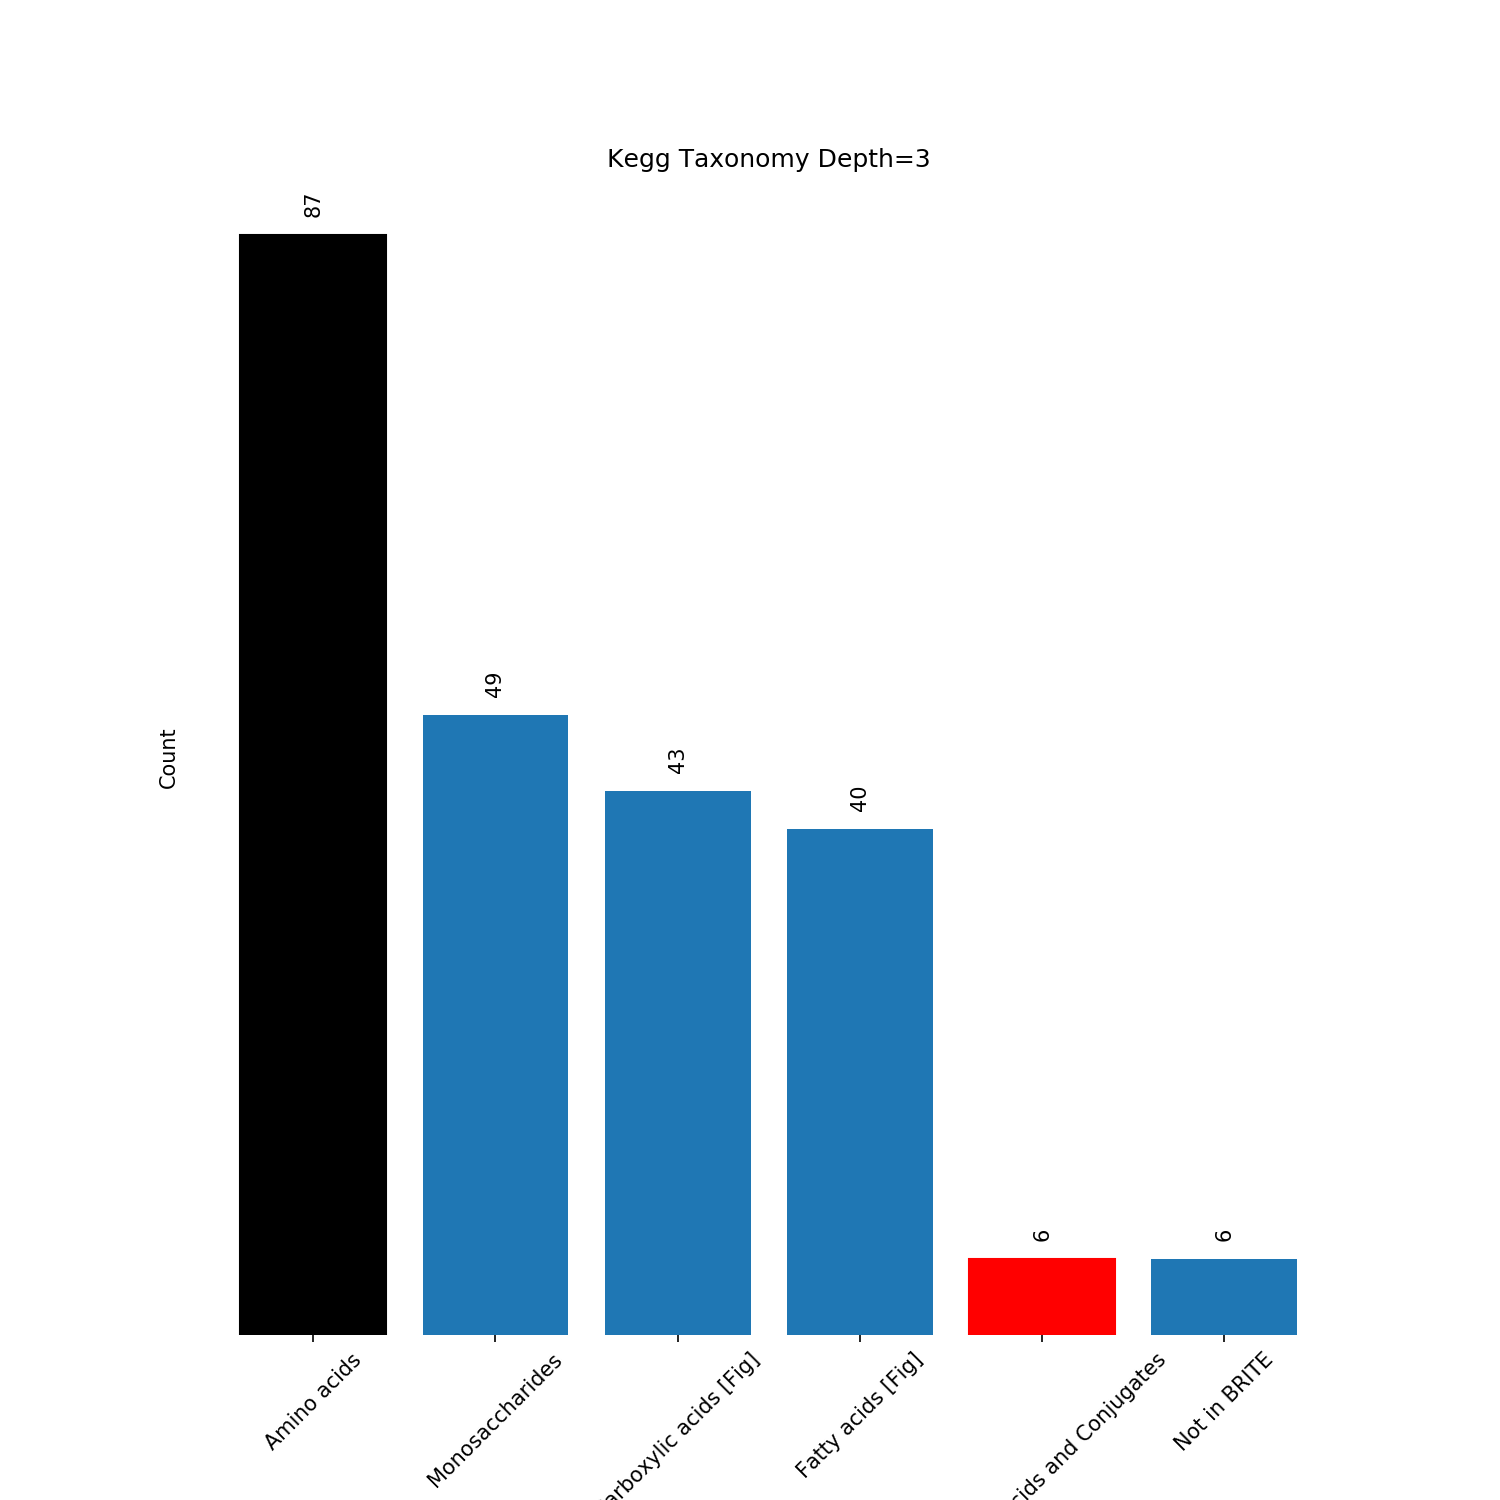

In [30]:
my_bar_percentage_chart(labels, count, ylabel='Count', xlabel='Group', title='Kegg Taxonomy Depth=3')

<IPython.core.display.Javascript object>


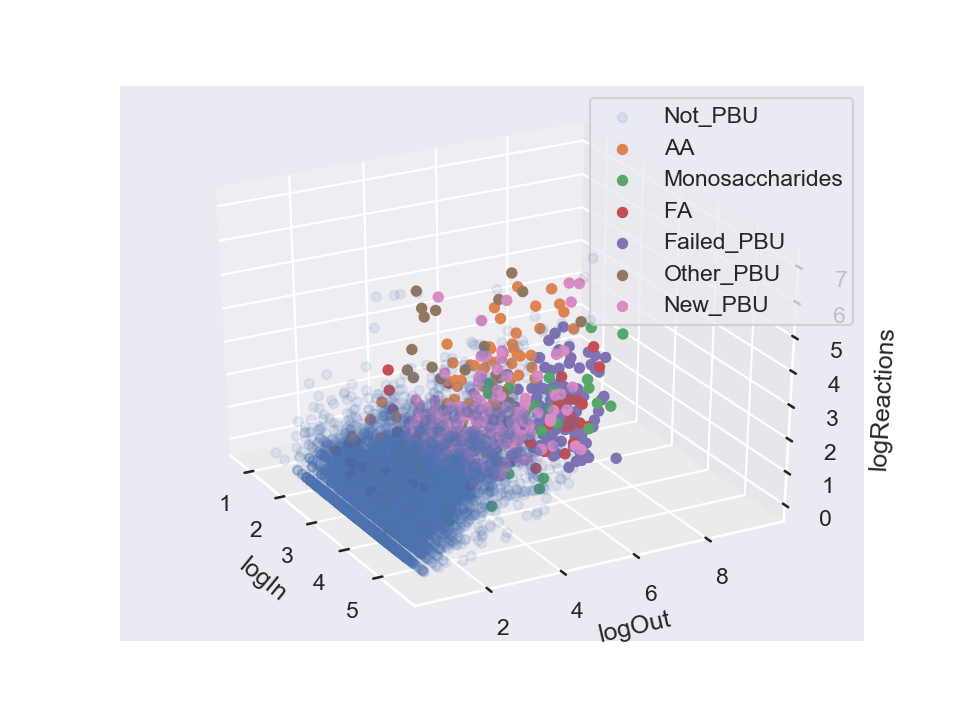

In [31]:

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

sns.set(style = "dark")

fig = plt.figure()
ax = fig.add_subplot(111, projection = '3d')

x = df_clean[df_clean['BRITE'] == 'Not_PBU']['logIn']
y = df_clean[df_clean['BRITE'] == 'Not_PBU']['logOut']
z = df_clean[df_clean['BRITE'] == 'Not_PBU']['logReactions']

ax.set_xlabel("logIn")
ax.set_ylabel("logOut")
ax.set_zlabel("logReactions")

ax.scatter(x, y, z, label='Not_PBU', alpha=0.1)

for br in ['AA', 'Monosaccharides', 'FA', 'Failed_PBU', 'Other_PBU', 'New_PBU']:

    x = df_clean[df_clean['BRITE'] == br]['logIn']
    y = df_clean[df_clean['BRITE'] == br]['logOut']
    z = df_clean[df_clean['BRITE'] == br]['logReactions']

    ax.scatter(x, y, z, label=br, alpha=1)
    
#ax.plot_surface(xx, yy, z_lim*np.ones((xx.shape[0], yy.shape[0])), alpha=0.1)
#ax.plot_surface(xx, y_lim*np.ones((xx.shape[0], yy.shape[0])), yy, alpha=0.1)
#ax.plot_surface(x_lim*np.ones((xx.shape[0], yy.shape[0])), xx, yy, alpha=0.1)
ax.legend()

<IPython.core.display.Javascript object>


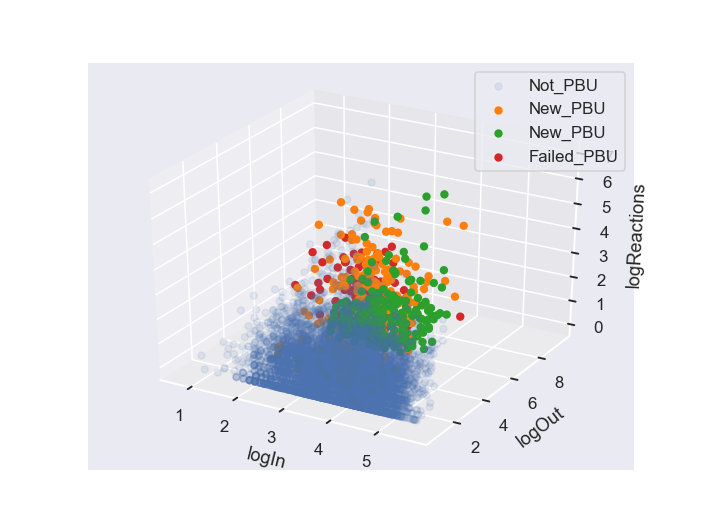

In [228]:

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

sns.set(style = "dark")

fig = plt.figure()
ax = fig.add_subplot(111, projection = '3d')

x = df_clean[df_clean['BRITE'] == 'Not_PBU']['logIn']
y = df_clean[df_clean['BRITE'] == 'Not_PBU']['logOut']
z = df_clean[df_clean['BRITE'] == 'Not_PBU']['logReactions']

ax.set_xlabel("logIn")
ax.set_ylabel("logOut")
ax.set_zlabel("logReactions")

ax.scatter(x, y, z, label='Not_PBU', alpha=0.1)

x = df_clean[df_clean['PBU'] == True]['logIn']
y = df_clean[df_clean['PBU'] == True]['logOut']
z = df_clean[df_clean['PBU'] == True]['logReactions']

colors = sns.color_palette("tab10")

ax.scatter(x, y, z, label=br, alpha=1, color=colors[1])

for k, br in enumerate(['New_PBU', 'Failed_PBU']):

    x = df_clean[df_clean['BRITE'] == br]['logIn']
    y = df_clean[df_clean['BRITE'] == br]['logOut']
    z = df_clean[df_clean['BRITE'] == br]['logReactions']

    ax.scatter(x, y, z, label=br, alpha=1, color=colors[k+2])
    
#ax.plot_surface(xx, yy, z_lim*np.ones((xx.shape[0], yy.shape[0])), alpha=0.1)
#ax.plot_surface(xx, y_lim*np.ones((xx.shape[0], yy.shape[0])), yy, alpha=0.1)
#ax.plot_surface(x_lim*np.ones((xx.shape[0], yy.shape[0])), xx, yy, alpha=0.1)
ax.legend()

In [230]:
labels

['Amino acids',
 'Monosaccharides',
 'Carboxylic acids [Fig]',
 'Fatty acids [Fig]',
 'FA01 Fatty Acids and Conjugates',
 'Not in BRITE']

Now we can proceed to obtain and analyse the hierarchies. If a compound has more than one hierarchy, the it counts double.

In [264]:
old_pbus_kegg = []
flag=True
for unique_code in mod_ids:
    if len(translator[unique_code])==1:
        old_pbus_kegg.append(translator[unique_code][0].split('_')[0])
    else:
        for element in translator[unique_code]:
            if '_' in list(element):
                old_pbus_kegg.append(element.split('_')[0])
                flag=False
                break
        if flag:
            old_pbus_kegg.append(translator[unique_code][0])
            
        flag=True
        
new_pbus_kegg = []
flag=True
for unique_code in new_pbus:
    if len(translator[unique_code])==1:
        new_pbus_kegg.append(translator[unique_code][0].split('_')[0])
    else:
        for element in translator[unique_code]:
            if '_' in list(element):
                new_pbus_kegg.append(element.split('_')[0])
                flag=False
                break
        if flag:
            new_pbus_kegg.append(translator[unique_code][0])
            
        flag=True

In [265]:
depth = 2

taxonomy = []
fails=0
#for code in df_clean[df_clean['PBU'] == True].index:
for code in new_pbus_kegg:
    #print(code)
    hierarchies = get_hierarchy(BRITE, code)
    if hierarchies:
        for key, hierarchy in hierarchies.items():
            taxonomy.append(hierarchy[depth])
    else:
        #pass
        taxonomy.append('Not in BRITE')
        
labels, count = np.unique(taxonomy, return_counts = True)
df_counter = pd.DataFrame({'Count':count}, index=labels)
df_counter = df_counter.sort_values(by =['Count'], axis=0, ascending=False)
#labels_or, count_or = list(df_counter.index), df_counter['Count'].values
labels_new, count_new = list(df_counter.index), df_counter['Count'].values

taxonomy = []
fails=0
for code in old_pbus_kegg:
#for code in new_pbus:
    #print(code)
    hierarchies = get_hierarchy(BRITE, code)
    if hierarchies:
        for key, hierarchy in hierarchies.items():
            taxonomy.append(hierarchy[depth])
    else:
        #pass
        taxonomy.append('Not in BRITE')
        
labels, count = np.unique(taxonomy, return_counts = True)
df_counter = pd.DataFrame({'Count':count}, index=labels)
df_counter = df_counter.sort_values(by =['Count'], axis=0, ascending=False)
labels_or, count_or = list(df_counter.index), df_counter['Count'].values
#labels_new, count_new = list(df_counter.index), df_counter['Count'].values

In [266]:
# I prefer working with list when the dimension is not very high

labels_new = list(labels_new)
labels_or = list(labels_or)
count_new = list(count_new)
count_or = list(count_or)

In [267]:
labels_or

['Peptides',
 'Carbohydrates',
 'FA  Fatty acyls',
 'Lipids',
 'Organic acids',
 'Fatty acids related compounds',
 'Not in BRITE',
 'Terpenoids']

In [268]:
for label in labels_new:
    if label not in labels_or:
        labels_or.append(label)
        count_or.append(0)

In [269]:
for label in labels_or:
    if label not in labels_new:
        labels_new.append(label)
        count_new.append(0)

In [270]:
labels_or

['Peptides',
 'Carbohydrates',
 'FA  Fatty acyls',
 'Lipids',
 'Organic acids',
 'Fatty acids related compounds',
 'Not in BRITE',
 'Terpenoids',
 'Nucleic acids',
 'Flavonoids',
 'ST  Sterol lipids',
 'PK  Polyketides',
 'PR  Prenol lipids',
 'Steroids',
 'Alkaloids',
 'N-glycosides',
 'O-glycosides',
 'Phenylpropanoids',
 'SL  Saccharolipids',
 'Vitamins and cofactors',
 'Hormones and transmitters',
 'Phytotoxins',
 'SP  Sphingolipids',
 'Amino acid related compounds',
 'Others']

In [271]:
labels_new

['Not in BRITE',
 'Nucleic acids',
 'Flavonoids',
 'Terpenoids',
 'ST  Sterol lipids',
 'PK  Polyketides',
 'PR  Prenol lipids',
 'Steroids',
 'FA  Fatty acyls',
 'Alkaloids',
 'N-glycosides',
 'O-glycosides',
 'Phenylpropanoids',
 'Carbohydrates',
 'Organic acids',
 'SL  Saccharolipids',
 'Vitamins and cofactors',
 'Hormones and transmitters',
 'Phytotoxins',
 'SP  Sphingolipids',
 'Peptides',
 'Amino acid related compounds',
 'Others',
 'Lipids',
 'Fatty acids related compounds']

In [272]:
count_or

[133,
 98,
 52,
 44,
 43,
 30,
 6,
 2,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [273]:
count_new

[101,
 28,
 20,
 20,
 18,
 16,
 16,
 15,
 12,
 9,
 9,
 9,
 9,
 4,
 3,
 2,
 2,
 2,
 1,
 1,
 1,
 1,
 1,
 0,
 0]

In [274]:
dict_new = dict(zip(labels_new, count_new))

In [275]:
count_new_2 = []
for label in labels_or:
    count_new_2.append(dict_new[label])

<IPython.core.display.Javascript object>


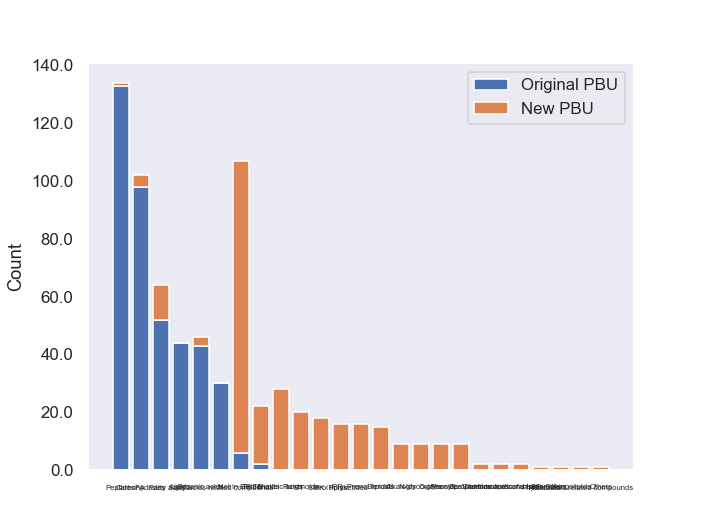

Text(0, 0.5, 'Count')

In [276]:
fig, ax = plt.subplots()
ax.bar(labels_or, count_or, label='Original PBU')
ax.bar(labels_or, count_new_2, bottom = count_or, label='New PBU')
ax.legend()
ax.set_xticklabels(labels_or, rotation = 0, fontsize=5)
ax.set_yticklabels(ax.get_yticks())
ax.set_ylabel('Count')

In [252]:
for pbu in new_pbus:
    print(translator[pbu])

['C05198']
['C00212']
['C00020']
['C00206']
['C00008']
['C00054']
['C01134']
['C00010']
['C00258']
['C00100', 'C02843']
['C00136']
['C00365']
['C01346']
['C05270']
['C01096']
['C00535']
['C01944']
['C05176']
['C00299']
['C00418']
['C00410']
['C00214']
['C00766']
['C00364']
['C00363']
['C00105']
['C00015']
['C12137']
['C00185']
['C00353']
['C02105']
['C01197', 'C01481']
['C04217']
['C01230']
['C09762']
['C00187']
['C04145']
['C00294']
['C00951']
['C08604']
['C00509']
['C00103']
['C00894']
['C04574']
['C00877']
['C00051', 'C02471']
['C02593']
['C00130']
['C00239']
['C01144']
['C00475']
['C00387']
['C00630']
['C01424']
['C06672']
['C01289']
['C00154']
['C00055']
['C00144']
['C00104']
['C01176']
['C00117']
['C00361']
['C03205']
['C00332']
['C03990']
['C00412']
['C00035']
['C04076']
['C04006']
['C15610']
['C12138']
['C00043']
['C00279']
['C01494']
['C00705']
['C05631']
['C02140']
['C00092']
['C08639']
['C00112']
['C00512']
['C00199']
['C06025']
['C06561']
['C01146']
['C01743']
['C00735']
['

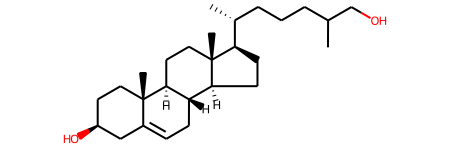

In [268]:
molecules[int(new_pbus[70].split('_')[1])]

In [244]:
for i, unique_id in enumerate(new_pbus):
        Chem.Draw.MolToFile(molecules[int(new_pbus[i].split('_')[1])], 'possible_new_pbus/'+str(unique_id)+'.png')

<IPython.core.display.Javascript object>


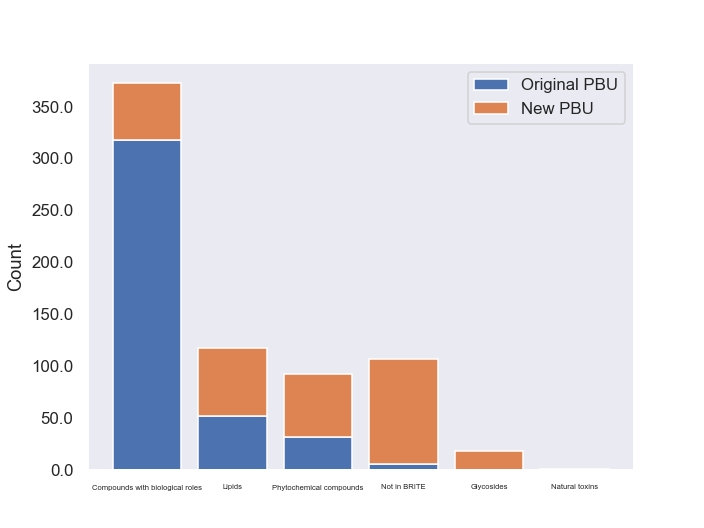

Text(0, 0.5, 'Count')

In [245]:
fig, ax = plt.subplots()
ax.bar(labels_or, count_or, label='Original PBU')
ax.bar(labels_or, count_new_2, bottom = count_or, label='New PBU')
ax.legend()
ax.set_xticklabels(labels_or, rotation = 0, fontsize=5)
ax.set_yticklabels(ax.get_yticks())
ax.set_ylabel('Count')

In [278]:
# TO DO:
lst = []
for index in df_clean.index:
    if index in new_pbus+mod_ids:
        lst.append(True)
    else:
        lst.append(False)
df_clean['PBU_final'] = lst
df_clean.head()

,Connections_out,Connections_in,MWeight,NCarbons,PBU,Reactions,logOut,logReactions,logIn,logCarbons,BRITE,PBU_final
ID,,,,,,,,,,,,
kegg_15303,13688.0,1.0,44.062600,3,False,1,9.524348,0.693147,0.693147,1.386294,Failed_PBU,False
kegg_348,11805.0,3.0,46.041865,2,False,10,9.376363,2.397895,1.386294,1.098612,Not_PBU,False
kegg_15775,11760.0,2.0,58.078250,4,False,1,9.372544,0.693147,1.098612,1.609438,Failed_PBU,False
kegg_3314,10355.0,5.0,60.057515,3,False,2,9.245321,1.098612,1.791759,1.386294,Failed_PBU,False
kegg_68,9719.0,3.0,44.026215,2,False,42,9.181941,3.761200,1.386294,1.098612,Not_PBU,False


<IPython.core.display.Javascript object>


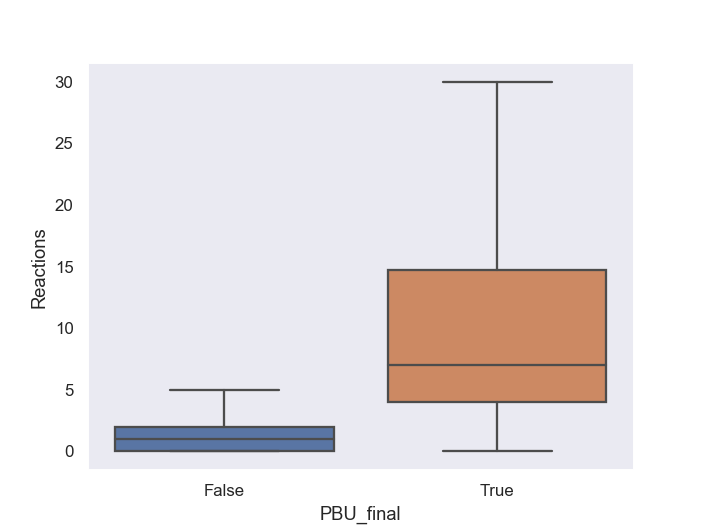

In [279]:
plt.figure()
sns.boxplot(x='PBU_final', y='Reactions', data=df_clean, showfliers = False)

In [293]:
with open('v2/new_pbu_kegg.pkl', 'wb') as f:
    pickle.dump(new_pbus, f)

In [13]:
with open('v2/new_pbu_kegg.pkl', 'rb') as f:
    new_pbus = pickle.load(f)

FileNotFoundError: [Errno 2] No such file or directory: 'v2/new_pbu_kegg.pkl'

In [18]:
lst = []
for kegg in new_pbus:
    if 'C00993' in translator[kegg]:
        print(translator[kegg])
        print(kegg)

['C00993']
kegg_701


In [19]:
with open('v2/PBU_v2.pkl', 'rb') as f:
    pbu_bbdd = pickle.load(f)

In [20]:
pbu_bbdd

[{'code': 'C00577',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C3H6O3/c4-1-3(6)2-5/h1,3,5-6H,2H2/t3-/m0/s1'},
 {'code': 'C02426',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C3H6O3/c4-1-3(6)2-5/h1,3,5-6H,2H2/t3-/m1/s1'},
 {'code': 'C01796',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C4H8O4/c5-2-1-8-4(7)3(2)6/h2-7H,1H2/t2-,3-,4?/m1/s1'},
 {'code': 'C06463',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C4H8O4/c5-2-1-8-4(7)3(2)6/h2-7H,1H2/t2-,3+,4?/m1/s1'},
 {'code': 'C00216',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3-,4+,5?/m1/s1'},
 {'code': 'C00259',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3-,4+,5?/m0/s1'},
 {'code': 'C00181',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3+,4-,5?/m1/s1'},
 {'code': 'C01510',
  'taxonomy': 'MS

In [285]:
inchis_pbu = [x['Inchi'] for x in pbu_bbdd]

In [284]:
lst = []
for kegg in new_pbus:
    code = translator[kegg]
    print(code)

['C00256']
['C05198']
['C00559']
['C00212']
['C00020']
['C00206']
['C00008']
['C00831']
['C00370']
['C00054']
['C05401']
['C01134']
['C00882']
['C00010']
['C00258']
['C07185']
['C00100', 'C02843']
['C00993']
['C00136']
['C02378']
['C00526']
['C01419']
['C00365']
['C01346']
['C05270']
['C00109']
['C01096']
['C18218']
['C04501']
['C06161']
['C00811']
['C00535']
['C00843']
['C01944']
['C06517']
['C05176']
['C00299']
['C00418']
['C00410']
['C05202']
['C00214']
['C00766']
['C00364']
['C00363']
['C00437']
['C00105']
['C01147']
['C08616']
['C00015']
['C00448']
['C00230']
['C12137']
['C00185']
['C00353']
['C02970']
['C02105']
['C01197', 'C01481']
['C00252']
['C04217']
['C01230']
['C04216']
['C09827']
['C09762']
['C04146']
['C01832']
['C00187']
['C17556']
['C02666']
['C04145']
['C00294']
['C00951']
['C01233']
['C00881']
['C08604']
['C05668']
['C00509']
['C00103']
['C00894']
['C04574']
['C00330']
['C00877']
['C00051', 'C02471']
['C02593']
['C00130']
['C00239']
['C01144']
['C00475']
['C00387']
['

In [21]:
depth = 3
brite = {}
taxonomy = []
brite_flag=False

new_pbu_complete = []
pbu_item = {}
for kegg in new_pbus:
    
    codes = translator[kegg]
    mol = df_clean.loc[codes[0]]['Molecule']
    inchi = Chem.MolToInchi(mol)
    
    if inchi in inchis_pbu:
        continue
        
    pbu_item['code'] = code
    pbu_item['source'] = 'kegg'
    pbu_item['Inchi'] = inchi
    
    hierarchies = get_hierarchy(BRITE, code)
    if hierarchies:
        for key, hierarchy in hierarchies.items():
            taxonomy = hierarchy[depth]
            if taxonomy == 'Amino acids':
                brite_flag = True
                tax = 'AA'
                break
            if taxonomy == 'Monosaccharides':
                brite_flag = True
                tax = 'Monosaccharides'
                break
            if taxonomy == 'Fatty acids [Fig]' or taxonomy[-1] == 'Fatty acids' or taxonomy[-1] == 'FA01 Fatty Acids and Conjugates':
                brite_flag=True
                tax = 'FA'
                break
        if brite_flag:
            pbu_item['taxonomy'] = tax
            brite_flag = False
    else:
        pbu_item['taxonomy'] = 'Not in BRITE'
    
    
    new_pbu_complete.append(pbu_item)
    
labels, count = np.unique([x['taxonomy'] for x in new_pbu_complete], return_counts = True)
print(dict(zip(labels, count)))

KeyError: 'C00256'

In [288]:
df_clean

,Connections_out,Connections_in,MWeight,NCarbons,PBU,Reactions,logOut,logReactions,logIn,logCarbons,BRITE,PBU_final
ID,,,,,,,,,,,,
kegg_15303,13688.0,1.0,44.062600,3,False,1,9.524348,0.693147,0.693147,1.386294,Failed_PBU,False
kegg_348,11805.0,3.0,46.041865,2,False,10,9.376363,2.397895,1.386294,1.098612,Not_PBU,False
kegg_15775,11760.0,2.0,58.078250,4,False,1,9.372544,0.693147,1.098612,1.609438,Failed_PBU,False
kegg_3314,10355.0,5.0,60.057515,3,False,2,9.245321,1.098612,1.791759,1.386294,Failed_PBU,False
kegg_68,9719.0,3.0,44.026215,2,False,42,9.181941,3.761200,1.386294,1.098612,Not_PBU,False
...,...,...,...,...,...,...,...,...,...,...,...,...
kegg_7418,1.0,29.0,400.381750,27,False,0,0.693147,0.000000,3.401197,3.332205,Not_PBU,False
kegg_5547,1.0,182.0,1196.582598,56,False,0,0.693147,0.000000,5.209486,4.043051,Not_PBU,False
kegg_6415,1.0,92.0,290.079038,15,False,0,0.693147,0.000000,4.532599,2.772589,Not_PBU,False
